# **Projeto de Estatística**

## **Importação das bibliotecas**

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Primeiro passo:

* Arquivos `.csv` em variáveis
* importação das tabelas com `pd.read_csv`

In [5]:
tabela1 = 'Tabelas/police.csv'
tabela2 = 'Tabelas/weather.csv'

In [6]:
tabela_policia = pd.read_csv(tabela1,
                             encoding='utf-8',
                             sep=',')

In [7]:
tabela_clima = pd.read_csv(tabela2,
                           encoding='utf-8',
                           sep=',')

## **Tópico 1**

**(A):** Número de registros e de variáveis

15 variáveis e 91741 registros

In [8]:
tabela_policia

,state,stop_date,stop_time,county_name,driver_gender,driver_race,violation_raw,violation,search_conducted,search_type,stop_outcome,is_arrested,stop_duration,drugs_related_stop,district
0,RI,2005-01-04,12:55,NaN,M,White,Equipment/Inspection Violation,Equipment,False,NaN,Citation,False,0-15 Min,False,Zone X4
1,RI,2005-01-23,23:15,NaN,M,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone K3
2,RI,2005-02-17,04:15,NaN,M,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone X4
3,RI,2005-02-20,17:15,NaN,M,White,Call for Service,Other,False,NaN,Arrest Driver,True,16-30 Min,False,Zone X1
4,RI,2005-02-24,01:20,NaN,F,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone X3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91736,RI,2015-12-31,21:21,NaN,F,Black,Other Traffic Violation,Moving violation,False,NaN,Citation,False,0-15 Min,False,Zone K2
91737,RI,2015-12-31,21:59,NaN,F,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone K3
91738,RI,2015-12-31,22:04,NaN,M,White,Other Traffic Violation,Moving violation,False,NaN,Citation,False,0-15 Min,False,Zone X3
91739,RI,2015-12-31,22:09,NaN,F,Hispanic,Equipment/Inspection Violation,Equipment,False,NaN,Warning,False,0-15 Min,False,Zone K3


**(B):** Número de valores faltosos em cada uma das variáveis
* state 0
* stop_date 0
* stop_time 0
* county_name 91741
* driver_gender 5205
* driver_race 5202
* violation_raw 5202
* violation 5202
* search_conducted 0
* search_type 88434
* stop_outcome 5202
* is_arrested 5202
* stop_duration 5202
* drugs_related_stop 0
* district 0

Para contabilizar o número de valores faltosos em cada variável eu posso usar um for em vez de fazer um por um, usando o `tabela.columns`

In [9]:
for coluna in tabela_policia.columns:
    print(coluna, tabela_policia[coluna].isnull().sum())

state 0
stop_date 0
stop_time 0
county_name 91741
driver_gender 5205
driver_race 5202
violation_raw 5202
violation 5202
search_conducted 0
search_type 88434
stop_outcome 5202
is_arrested 5202
stop_duration 5202
drugs_related_stop 0
district 0


**(C):** Eliminando colunas inúteis 

In [10]:
tabela_policia = tabela_policia.drop(columns=['county_name', 'state']) #Usamos o tabela.drop e passamos uma lista de colunas 

**(D):** Eliminando os registros inúteis da variável de gênero. Por se tratar de uma variável muito importante, registros em que ela não exista serão inúteis.

In [11]:
tabela_policia.driver_gender = tabela_policia.driver_gender.dropna()

**(E):** Classificação e mudança de algumas variáveis
* `search_conducted` : tipo booleano
* `is_arrested` : tipo booleano (estava como object)
* `district` : string 

In [12]:
tabela_policia.is_arrested.info()

<class 'pandas.Series'>
RangeIndex: 91741 entries, 0 to 91740
Series name: is_arrested
Non-Null Count  Dtype 
--------------  ----- 
86539 non-null  object
dtypes: object(1)
memory usage: 716.9+ KB


In [13]:
tabela_policia.is_arrested = tabela_policia.is_arrested.astype('bool')

**(F):** União de duas colunas: `tempo` e `hora`. 

In [14]:
tabela_policia['stop_datetime'] = tabela_policia['stop_time'] + ' ' + tabela_policia['stop_date']

In [15]:
tabela_policia['stop_datetime'] = pd.to_datetime(tabela_policia['stop_datetime']) #pd.to_datetime

**(G):** Colocando a nova coluna como index do nosso conjunto de dados

In [16]:
tabela_policia = tabela_policia.set_index('stop_datetime')

#### **Fim do tópico 1**

In [17]:
tabela_policia

,stop_date,stop_time,driver_gender,driver_race,violation_raw,violation,search_conducted,search_type,stop_outcome,is_arrested,stop_duration,drugs_related_stop,district
stop_datetime,,,,,,,,,,,,,
2005-01-04 12:55:00,2005-01-04,12:55,M,White,Equipment/Inspection Violation,Equipment,False,NaN,Citation,False,0-15 Min,False,Zone X4
2005-01-23 23:15:00,2005-01-23,23:15,M,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone K3
2005-02-17 04:15:00,2005-02-17,04:15,M,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone X4
2005-02-20 17:15:00,2005-02-20,17:15,M,White,Call for Service,Other,False,NaN,Arrest Driver,True,16-30 Min,False,Zone X1
2005-02-24 01:20:00,2005-02-24,01:20,F,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone X3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2015-12-31 21:21:00,2015-12-31,21:21,F,Black,Other Traffic Violation,Moving violation,False,NaN,Citation,False,0-15 Min,False,Zone K2
2015-12-31 21:59:00,2015-12-31,21:59,F,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone K3
2015-12-31 22:04:00,2015-12-31,22:04,M,White,Other Traffic Violation,Moving violation,False,NaN,Citation,False,0-15 Min,False,Zone X3


## **Tópico 2**

**(A):**  Qual a infração mais comum e a menos notificada?

A violação mais notada é `speeding`, a menos notada é `seat belt`

In [18]:
tabela_policia.violation.value_counts()

violation
Speeding               48424
Moving violation       16224
Equipment              10922
Other                   4410
Registration/plates     3703
Seat belt               2856
Name: count, dtype: int64

**(B):** O interesse agora é responder a seguinte questão: motoristas do sexo masculino e feminino tendem a cometer diferentes tipos de infrações de trânsito?

Homens tendem a cometer mais infrações que as mulheres em todos os tipos possíveis, tanto em valor bruto como proporcional. Informação atrelada a quantidade maior de homens que dirigem em relação às mulheres

In [19]:
pd.crosstab(tabela_policia['violation'].values, tabela_policia['driver_gender'].values,
            rownames= ['Acidentes'],
            colnames=['Gênero'],
            margins=True)

Gênero,F,M,All
Acidentes,,,
Equipment,2501,8420,10921
Moving violation,3286,12938,16224
Other,707,3702,4409
Registration/plates,1056,2647,3703
Seat belt,578,2278,2856
Speeding,15646,32777,48423
All,23774,62762,86536


In [20]:
pd.crosstab(tabela_policia['violation'].values, tabela_policia['driver_gender'].values,
            rownames= ['Acidentes'],
            colnames=['Gênero'],
            margins=True,
            normalize=True)

Gênero,F,M,All
Acidentes,,,
Equipment,0.028901,0.097301,0.126202
Moving violation,0.037973,0.149510,0.187483
Other,0.008170,0.042780,0.050950
Registration/plates,0.012203,0.030588,0.042791
Seat belt,0.006679,0.026324,0.033004
Speeding,0.180803,0.378767,0.559571
All,0.274730,0.725270,1.000000


**(C):** Gráfico com as informações do `crosstab`

In [21]:
tabela_contigencia = pd.crosstab(tabela_policia['violation'].values, tabela_policia['driver_gender'].values,
                                rownames= ['Acidentes'],
                                colnames=['Gênero'],
                                margins=True)

<Axes: xlabel='Acidentes'>

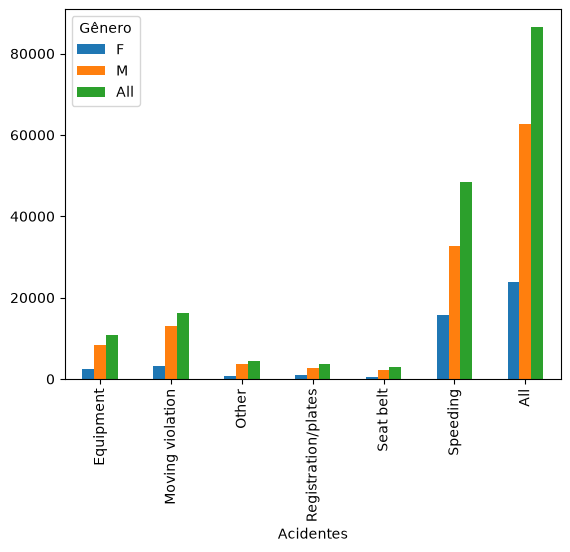

In [22]:
tabela_contigencia.plot.bar()

**(D):**  Quando um motorista é parado por excesso de velocidade, muitas pessoas acreditam que o gênero influencia se o motorista receberá uma multa ou um aviso. Você pode encontrar evidências disso no conjunto de dados?

Não existe uma diferença visível nos gêneros com relação a aviso ou citação, na verdade, proporcionalmente, mulheres recebem mais citação que homens com relação ao todo.

In [23]:
pd.crosstab(tabela_policia['driver_gender'].values, tabela_policia['stop_outcome'].values,
            rownames= ['Genero'],
            colnames=['Resultado_abordagem'],
            margins=True) 

Resultado_abordagem,Arrest Driver,Arrest Passenger,Citation,N/D,No Action,Warning,All
Genero,,,,,,,
F,556,113,21251,168,201,1485,23774
M,2179,230,55840,439,423,3651,62762
All,2735,343,77091,607,624,5136,86536


**(E):** Contagem do número de revistas em abordagens, sem distinção de gênero

In [24]:
tabela_policia.search_conducted.value_counts(normalize=True)

search_conducted
False    0.963953
True     0.036047
Name: proportion, dtype: float64

**(F):** O gênero afeta a escolha de veículos a serem revistados?

Dentro da pequena porcentagem de veículos em que foram realizadas revistas, há mais homens do que mulheres.

In [25]:
tabela_policia.groupby('driver_gender')['search_conducted'].value_counts(normalize=True)

driver_gender  search_conducted
F              False               0.980819
               True                0.019181
M              False               0.954574
               True                0.045426
Name: proportion, dtype: float64

**(G):**  Considere agora a hipótese de que a taxa de revista varia de acordo com o tipo de infração, e a diferença na taxa de revista entre homens e mulheres é porque eles tendem a cometer infrações diferentes.

Homens, no geral, tem bem mais taxa de revista em todos os tipos de infrações.

Usei o `normalize = 'index'`

In [26]:
pd.crosstab(
    index=[tabela_policia['driver_gender'].values, tabela_policia['violation'].values],
    columns=tabela_policia['search_conducted'].values, 
    rownames=['Gênero', 'Tipo de Infração'],
    colnames=['Foi Revistado?'],
    normalize='index'
) *100


Foi Revistado?                  False      True 
Gênero Tipo de Infração                         
F      Equipment            96.001599   3.998401
       Moving violation     96.074254   3.925746
       Other                95.898161   4.101839
       Registration/plates  94.507576   5.492424
       Seat belt            98.269896   1.730104
       Speeding             99.169117   0.830883
M      Equipment            92.850356   7.149644
       Moving violation     93.847581   6.152419
       Other                95.380875   4.619125
       Registration/plates  89.119758  10.880242
       Seat belt            96.488147   3.511853
       Speeding             97.211459   2.788541

## **Tópico 3**

**(A):** calculando a taxa de prisão em todas as paradas no DataFrame, calculando a média da coluna `is_arrested`

In [27]:
tabela_policia.is_arrested.mean() #media de valores booleanos, significa os True/Todos

np.float64(0.09025408486936048)

**(B):** calculando a taxa de prisão por hora usando o atributo de hora do índice. A hora varia de 0 a 23, considerando que 0 é meia noite e 12h é meio dia.

In [28]:
tabela_policia.groupby(tabela_policia.index.hour)['is_arrested'].mean()

stop_datetime
0     0.121206
1     0.144250
2     0.144120
3     0.148370
4     0.179310
5     0.178899
6     0.043614
7     0.053497
8     0.073591
9     0.070199
10    0.069306
11    0.075217
12    0.087040
13    0.078964
14    0.080171
15    0.080526
16    0.089505
17    0.107914
18    0.089883
19    0.078508
20    0.091482
21    0.153265
22    0.110715
23    0.108225
Name: is_arrested, dtype: float64

**(C):** criando um gráfico de linha mostrando a variável `hourly_arrest_rate`, colocando o rótulo Horas no eixo-x, e Taxa de Prisões, no eixo-y, e o título de Taxa de Prisões por Hora do Dia.

A taxa de prisão costuma ser maior nas 4/5 da manhã

In [29]:
hourly_arrest_rate = tabela_policia.groupby(tabela_policia.index.hour)['is_arrested'].mean()

Text(0.5, 1.0, 'Taxa de Prisões por Hora do Dia')

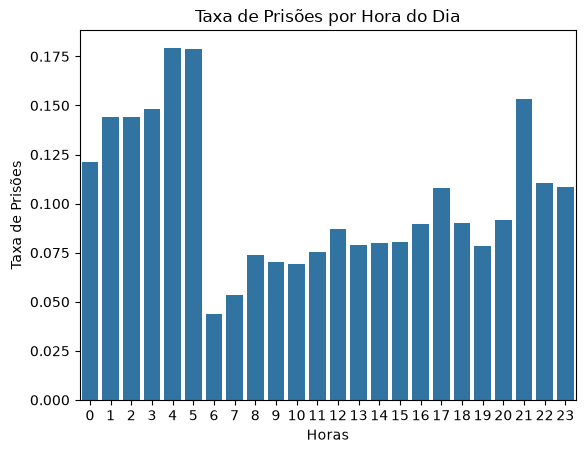

In [30]:
grafico = sns.barplot(x = hourly_arrest_rate.index, y = hourly_arrest_rate.values )
grafico.set_xlabel("Horas")
grafico.set_ylabel('Taxa de Prisões')
grafico.set_title('Taxa de Prisões por Hora do Dia')

**(D):** calculando a taxa anual de drogas reamostrando essa coluna e, em seguida, usando um gráfico de linha para
visualizar como a taxa mudou ao longo do tempo;

In [31]:
grafico = tabela_policia.groupby(tabela_policia.index.year)['drugs_related_stop'].mean()

<Axes: xlabel='stop_datetime'>

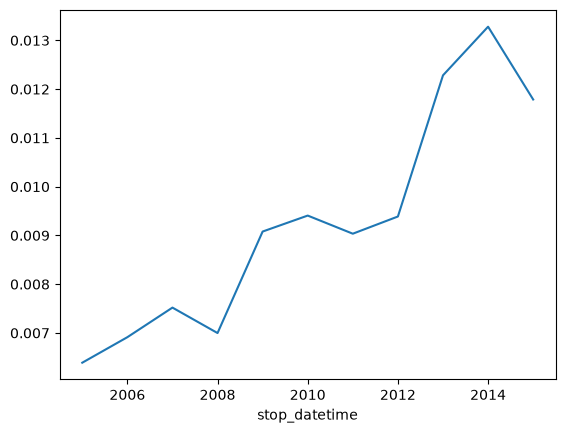

In [32]:
sns.lineplot(x = grafico.index, y = grafico.values)

**(E):** Ainda falando sobre drogas, consideremos a hipótese de que, o aumento ou a diminuição das apreensões de drogas estão associadas ao aumento ou diminuição das abordagens políciais, ou seja, mais abordagens, geram mais apreensões e menos abordagens, menos apreensões de drogas. Podemos testar essa hipótese calculando a taxa de abordagens anual e, em seguida, comparando-a com a taxa anual de medicamentos.

Não existe uma relação direta nem de correlação e nem de causalidade com a quantidade de buscas e a quantidade de drogas apreendidas.

In [33]:
grafico1 = tabela_policia.groupby(tabela_policia.index.year)['search_conducted'].mean()
grafico2 = tabela_policia.groupby(tabela_policia.index.year)['drugs_related_stop'].mean()

In [34]:
tabela_teste = pd.concat([grafico1, grafico2], axis=1)
tabela_teste

,search_conducted,drugs_related_stop
stop_datetime,,
2005,0.048323,0.006390
2006,0.039773,0.006913
2007,0.041567,0.007520
2008,0.037585,0.006998
2009,0.045780,0.009079
2010,0.041808,0.009407
2011,0.033129,0.009035
2012,0.031808,0.009388
2013,0.028164,0.012283


<Axes: xlabel='stop_datetime'>

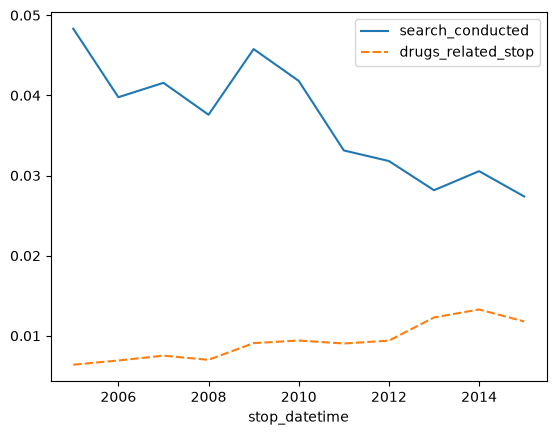

In [35]:
sns.lineplot(data = tabela_teste)

**(F):** O estado de Rhode Island está dividido em seis distritos policiais, também conhecidos como zonas. Como as zonas se comparam em termos de quais infrações são detectadas pela polícia?

As três zonas são completamente proporcionais quanto aos crimes, possuem quantidades muito parecidas em suas respectivas proporções.

In [36]:
tabela_teste = pd.crosstab(tabela_policia['district'].values, tabela_policia['violation'].values)

<Axes: xlabel='row_0'>

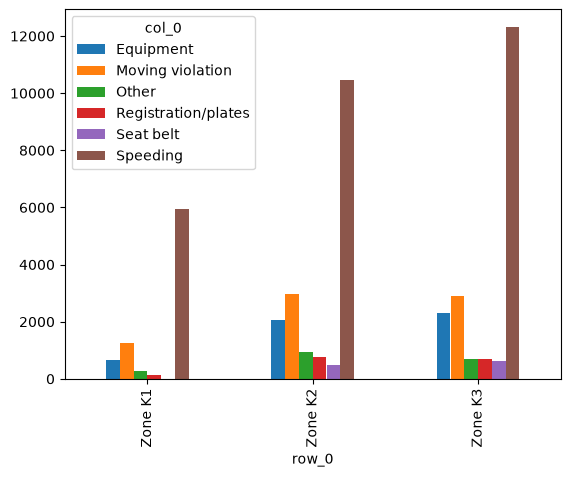

In [37]:
grafico = tabela_teste.iloc[:3,:]
grafico.plot.bar()

## **Tópico 4**

**(A):** imprimindo as principais medidas resumo usando o comando describe e plotando os três boxplots dessas
variáveis em um mesmo gráfico.

Na maior parte dos boxplots, o bigode de baixo é maior que o de cima, indicando valores muitos dispersos abaixo da media, o que significa que eles são mais incomuns que os valores maiores. Com relação a caixa, todas são muito compactas, indicando pouca variedade e boa previsibilidade.

In [38]:
tabela_clima[['TMIN', 'TAVG', 'TMAX']].describe()

,TMIN,TAVG,TMAX
count,4017.000000,1217.000000,4017.000000
mean,43.484441,52.493016,61.268608
std,17.020298,17.830714,18.199517
min,-5.000000,6.000000,15.000000
25%,30.000000,39.000000,47.000000
50%,44.000000,54.000000,62.000000
75%,58.000000,68.000000,77.000000
max,77.000000,86.000000,102.000000


<Axes: >

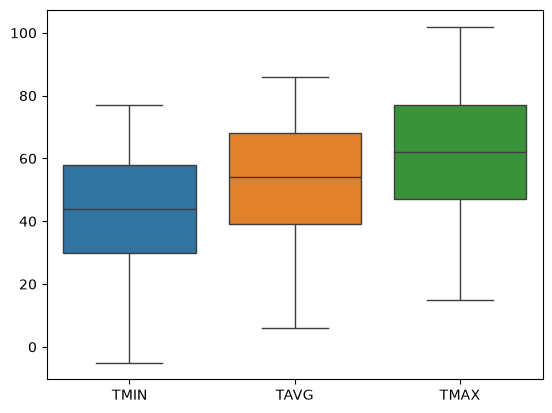

In [40]:
sns.boxplot(tabela_clima[['TMIN', 'TAVG', 'TMAX']])

**(B):** Para a variável TDIFF, que representa a diferença entre as temperaturas, o que pode dizer sobre a distribuição de dados?

Não há formação de calda e os dados concentram-se bem no meio do gráfico, indicando uma media próxima da mediana.

In [41]:
tabela_clima['TDIFF'] = tabela_clima['TMAX'] - tabela_clima['TMIN']

<Axes: ylabel='Frequency'>

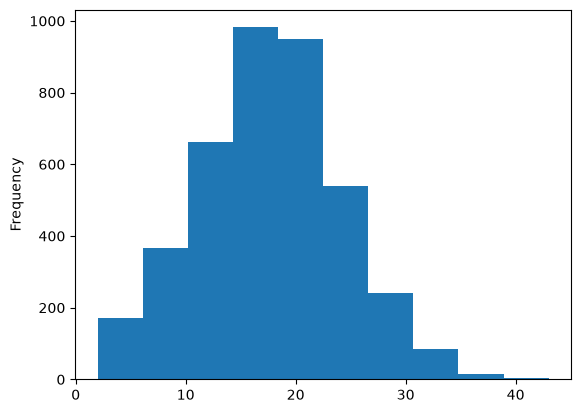

In [42]:
tabela_clima['TDIFF'].plot.hist()

**(C):** preparando os DataFrames das abordagens de trânsito e de classificação do
clima (o dessa sessão) para que estejam prontos para serem mesclados.

In [43]:
tabela_policia = tabela_policia.reset_index()

In [44]:
colunas_clima = tabela_clima.loc[:, 'WT01':'WT22']
tabela_clima['RATING'] = colunas_clima.sum(axis=1)

In [45]:
tabela_teste = tabela_clima[['DATE', 'RATING']]

**(D):** mesclando os dataframes gerados em um novo dataframe, unidos usando a coluna
`stop_date` de do dataframe policial e a coluna `DATE` do novo dataframe gerado a partir
dos dados meteorológicos. Definindo `stop_datetime`
novamente como o índice.

In [46]:
tabela_final = pd.merge(tabela_policia, tabela_teste, how = 'inner', left_on='stop_date', right_on='DATE')

In [47]:
tabela_final = tabela_final.set_index('stop_datetime')

In [48]:
tabela_final = tabela_final.drop(columns= ['stop_time', 'stop_date', 'DATE'])

In [49]:
tabela_final

,driver_gender,driver_race,violation_raw,violation,search_conducted,search_type,stop_outcome,is_arrested,stop_duration,drugs_related_stop,district,RATING
stop_datetime,,,,,,,,,,,,
2005-01-04 12:55:00,M,White,Equipment/Inspection Violation,Equipment,False,NaN,Citation,False,0-15 Min,False,Zone X4,4.0
2005-01-23 23:15:00,M,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone K3,6.0
2005-02-17 04:15:00,M,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone X4,0.0
2005-02-20 17:15:00,M,White,Call for Service,Other,False,NaN,Arrest Driver,True,16-30 Min,False,Zone X1,1.0
2005-02-24 01:20:00,F,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone X3,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2015-12-31 21:21:00,F,Black,Other Traffic Violation,Moving violation,False,NaN,Citation,False,0-15 Min,False,Zone K2,1.0
2015-12-31 21:59:00,F,White,Speeding,Speeding,False,NaN,Citation,False,0-15 Min,False,Zone K3,1.0
2015-12-31 22:04:00,M,White,Other Traffic Violation,Moving violation,False,NaN,Citation,False,0-15 Min,False,Zone X3,1.0
